# AI651 PA3 — Deep Learning for Space, Time and Graphs (runner notebook)

Run the cells top to bottom. The notebook:
1. mounts Google Drive (all results and the processed dataset are cached there, so a disconnect does not lose work),
2. asks you to upload **`pa3_code.zip`**,
3. runs one script per question and displays every figure/table for the report.

**Runtime:** use a GPU runtime (*Runtime → Change runtime type → T4 GPU*) for Q4–Q5. CPU works too (set `STRIDE = 2` or `3` below).
Training is resumable: rerunning a cell continues from the last epoch; finished models are skipped.

In [1]:
# 1) Mount Drive and choose folders
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/AI651_PA3'           # change if you like
os.environ['PA3_DATA_DIR'] = f'{BASE}/data'          # processed SD tensor (cached on Drive)
os.environ['PA3_OUT_DIR']  = f'{BASE}/outputs'       # figures, tables, metrics, checkpoints
os.environ['PA3_RAW_DIR']  = '/content/largest_raw'  # big raw Kaggle files on fast local disk (only needed once)
for d in (BASE, os.environ['PA3_DATA_DIR'], os.environ['PA3_OUT_DIR'], os.environ['PA3_RAW_DIR']):
    os.makedirs(d, exist_ok=True)
print('Outputs will be saved to', os.environ['PA3_OUT_DIR'])

Mounted at /content/drive
Outputs will be saved to /content/drive/MyDrive/AI651_PA3/outputs


In [2]:
# 2) Upload pa3_code.zip and unpack it to /content/pa3
from google.colab import files
import zipfile, shutil, glob
up = files.upload()
zname = next(iter(up))
shutil.rmtree('/content/pa3', ignore_errors=True)
with zipfile.ZipFile(zname) as z:
    z.extractall('/content/_pa3_unzip')
common = glob.glob('/content/_pa3_unzip/**/common.py', recursive=True)[0]
shutil.move(os.path.dirname(common), '/content/pa3')
shutil.rmtree('/content/_pa3_unzip', ignore_errors=True)
shutil.copy(zname, f'{BASE}/pa3_code.zip')   # keep a copy on Drive
CODE = '/content/pa3'
print(sorted(os.listdir(CODE)))

Saving pa3_code.zip to pa3_code.zip
['README.md', 'common.py', 'data_utils.py', 'largest_io.py', 'models.py', 'q1_aggregation.py', 'q2_direction.py', 'q3_dataset.py', 'q4_stgnn.py', 'q5_adjacency.py', 'q6_analysis.py', 'q7_report.py', 'requirements.txt', 'train.py']


In [3]:
# 3) Extra packages (PyTorch, NumPy, pandas, matplotlib are preinstalled on Colab)
!pip -q install h5py hdf5plugin tables tabulate kaggle psutil

In [4]:
# 4) Configuration + display helpers
import torch, glob
from IPython.display import Image, Markdown, display

GPU = torch.cuda.is_available()
print('GPU:', torch.cuda.get_device_name(0) if GPU else 'none (CPU)')

EPOCHS   = 30     # max epochs (early stopping on validation MAE, patience 6)
HIDDEN   = 32     # hidden dimension d (assignment: 16-32)
BATCH    = 64
LR       = 1e-3
EMB_DIM  = 10     # node-embedding dimension for the adaptive graph
TOPK     = 0      # 0 = dense learned graph; e.g. 20 keeps top-20 neighbours per node
SEED     = 42
STRIDE   = 1 if GPU else 2   # >1 subsamples training windows to speed up CPU training
TRAIN_ARGS = (f'--epochs {EPOCHS} --hidden {HIDDEN} --batch_size {BATCH} --lr {LR} '
              f'--emb_dim {EMB_DIM} --topk {TOPK} --seed {SEED} --train_stride {STRIDE}')
print(TRAIN_ARGS)

FIG = os.path.join(os.environ['PA3_OUT_DIR'], 'figures')
RES = os.path.join(os.environ['PA3_OUT_DIR'], 'results')
def show(prefix):
    for p in sorted(glob.glob(f'{FIG}/{prefix}*.png')):
        print(os.path.basename(p)); display(Image(p))
def show_md(name):
    p = os.path.join(RES, name)
    if os.path.exists(p):
        display(Markdown(open(p).read()))

GPU: Tesla T4
--epochs 30 --hidden 32 --batch_size 64 --lr 0.001 --emb_dim 10 --topk 0 --seed 42 --train_stride 1


## Question 1 — What does a sum remember?


  Q1(a)  Affine message  phi(x) = w x + c
sum_{u in N(v)} (w x_u + c) = w * S_v + c * n_v   ->  h_v = rho(w S_v + c n_v)
The aggregate depends on the neighbourhood ONLY through (n_v, S_v), so two
neighbourhoods with equal n_v and S_v give the same input to rho for every w, c, rho.
  [0, 0] vs [-1, 1]: n=2,2  S=0,0  steady=2,0  -> max |h_A - h_B| over 1000 random (w,c,rho) = 2.66e-15
  [-1, 0, 0, 1] vs [-1, -1, 1, 1]: n=4,4  S=0,0  steady=2,0  -> max |h_A - h_B| over 1000 random (w,c,rho) = 3.77e-15

  Q1(b)  Injective scalar message, K = 8
Base B = K + 1 = 9:  phi(-1) = 1,  phi(0) = B = 9,  phi(+1) = B^2 = 81
Sum = n_slow*1 + n_steady*B + n_fast*B^2. Every count is <= K < B, so each count
occupies its own base-B digit (no carries) -> decode with mod / integer division.
  #valid count triples (1 <= n <= 8): 164
  all sums distinct: True
  decode(sum) recovers (slow, steady, fast) for every triple: True
  verified on every neighbourhood multiset of size 1..8: True
  sanity: base K = 8 i

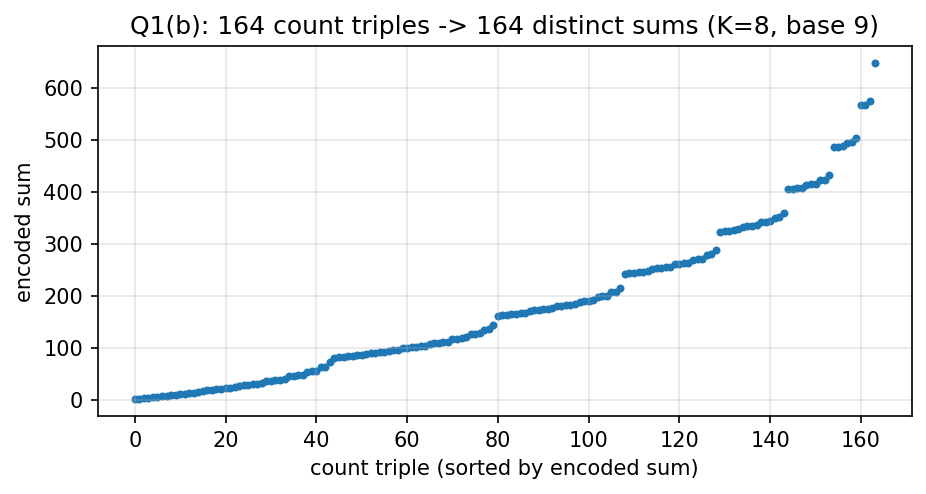

| Task                        | Method   | Possible   | Reason                                                                                  |
|:----------------------------|:---------|:-----------|:----------------------------------------------------------------------------------------|
| (i) Count steady neighbours | Sum      | Yes        | rho = a2 (2nd coordinate = #steady) [verified on all neighbourhoods]                    |
| (i) Count steady neighbours | Mean     | No         | N1=[0] and N2=[0, 0] both aggregate to (0, 1, 0) but answers are 1 vs 2                 |
| (i) Count steady neighbours | Max      | No         | N1=[0] and N2=[0, 0] both aggregate to (0, 1, 0) but answers are 1 vs 2                 |
| (ii) More than half slowing | Sum      | Yes        | n = a1+a2+a3 (sum of all coords); test a1 > n/2 [verified on all neighbourhoods]        |
| (ii) More than half slowing | Mean     | Yes        | a1 = fraction slowing; test a1 > 1/2 [verified on all neighbourhoods]                   |
| (ii) More than half slowing | Max      | No         | N1=[-1, -1, 0] and N2=[-1, 0] both aggregate to (1, 1, 0) but answers are True vs False |
| (iii) Any neighbour slowing | Sum      | Yes        | test a1 > 0 (#slowing >= 1) [verified on all neighbourhoods]                            |
| (iii) Any neighbour slowing | Mean     | Yes        | test a1 > 0 (fraction slowing > 0) [verified on all neighbourhoods]                     |
| (iii) Any neighbour slowing | Max      | Yes        | test a1 = 1 (some neighbour flagged slowing) [verified on all neighbourhoods]           |

In [5]:
!cd {CODE} && python q1_aggregation.py
show('q1')
show_md('q1c_table.md')

## Question 2 — Which way is the slowdown moving?


  Q2(a)i  Fit a, b on one impulse at sensor 20
Predictions: x_hat_19 = b, x_hat_20 = a, x_hat_21 = b, others 0
Targets    : y_19 = 1,   y_20 = 0,   y_21 = 0
SSE(a,b) = (b-1)^2 + a^2 + b^2
dSSE/da = 2a = 0          -> a = 0
dSSE/db = 2(b-1) + 2b = 0 -> b = 1/2,   minimum SSE = 1/4 + 1/4 = 1/2
Numeric lstsq: a = 0.000000, b = 0.500000, SSE = 0.5000
Sensors 19 and 21 receive the SAME prediction (0.5): the symmetric layer cannot tell
which side the slowdown is moving to, so it hedges half-half.

  Q2(a)ii  20-step rollout of a Gaussian bump
[fig] saved /content/drive/MyDrive/AI651_PA3/outputs/figures/q2a_heatmaps.png
  t= 0: centre true=20.00 pred=20.00 | peak true=1.000 pred=1.000 | mass true=5.013 pred=5.013
  t= 5: centre true=15.00 pred=20.00 | peak true=1.000 pred=0.656 | mass true=5.013 pred=5.013
  t=10: centre true=10.00 pred=20.00 | peak true=1.000 pred=0.528 | mass true=5.013 pred=5.013
  t=20: centre true=0.00 pred=20.00 | peak true=1.000 pred=0.405 | mass true=5.013 pred=5.013

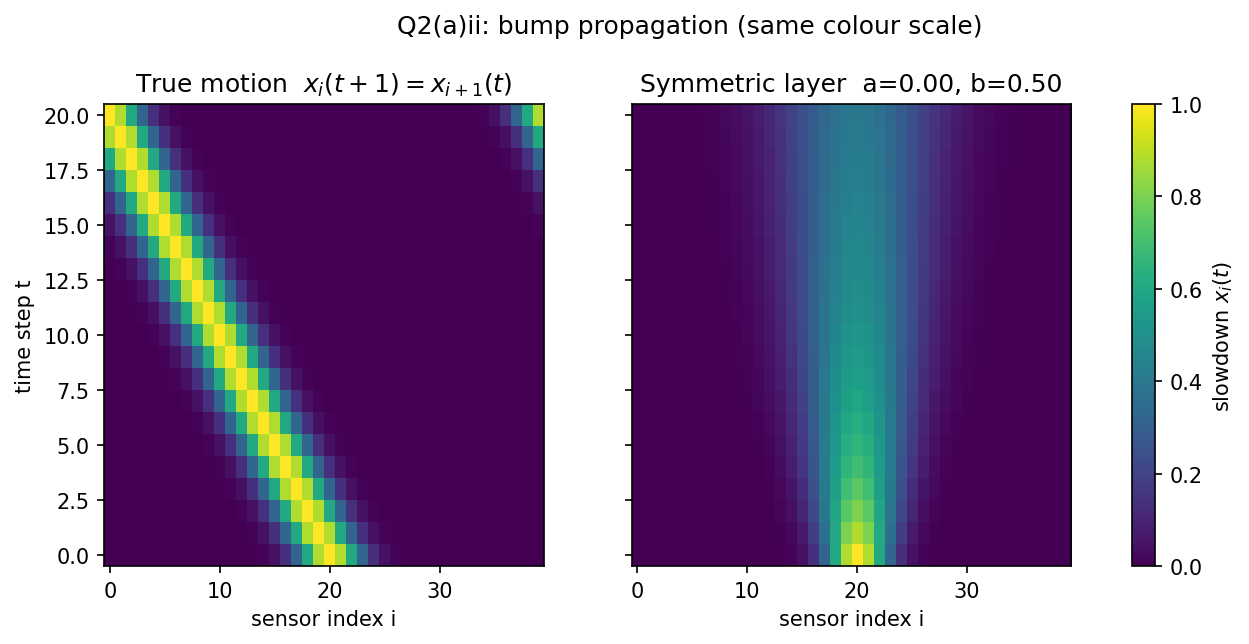

q2a_profiles_t20.png


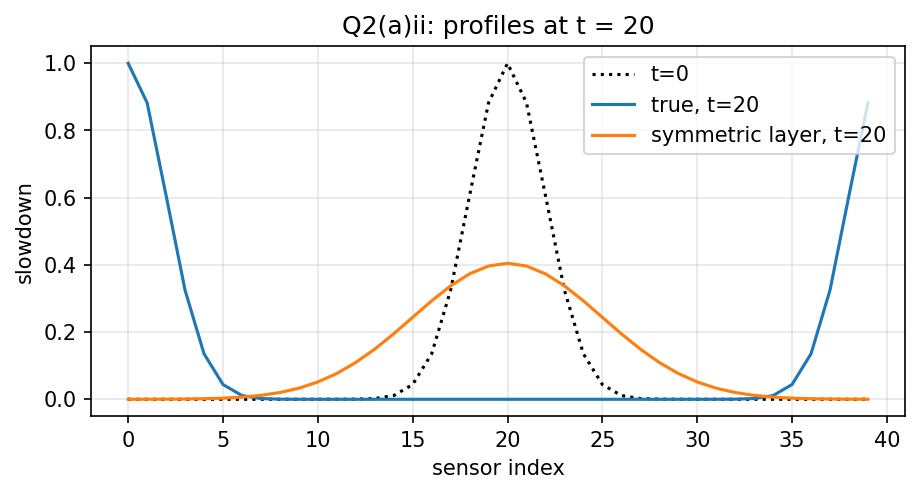

q2b_heatmaps.png


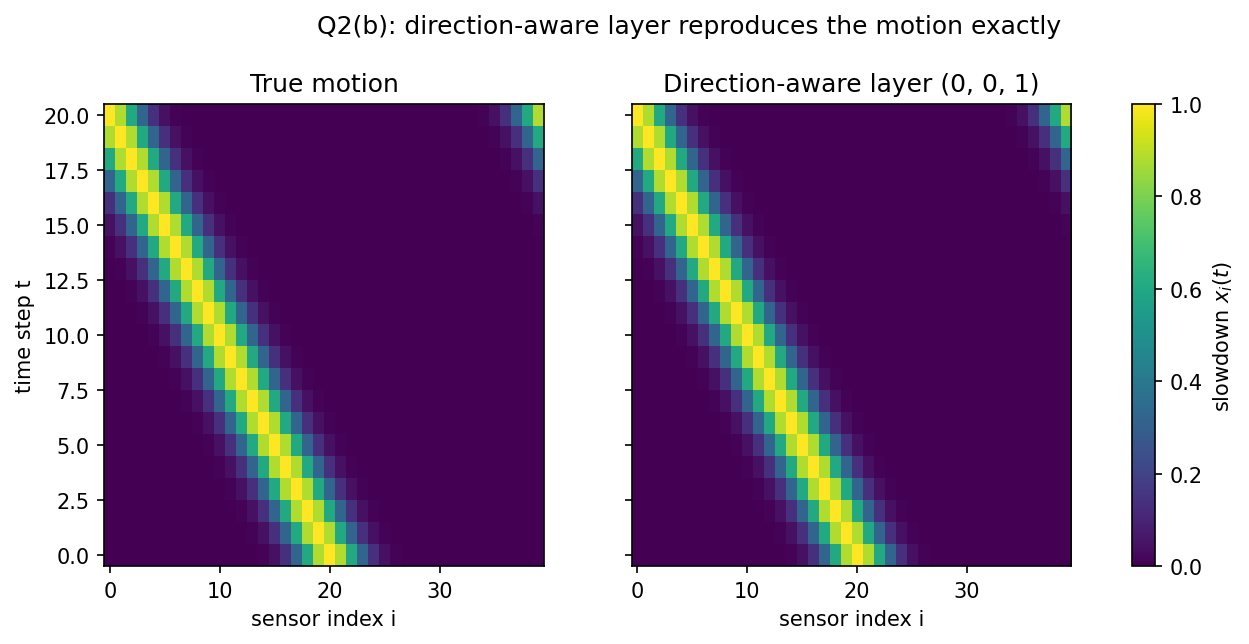

q2c_heatmaps.png


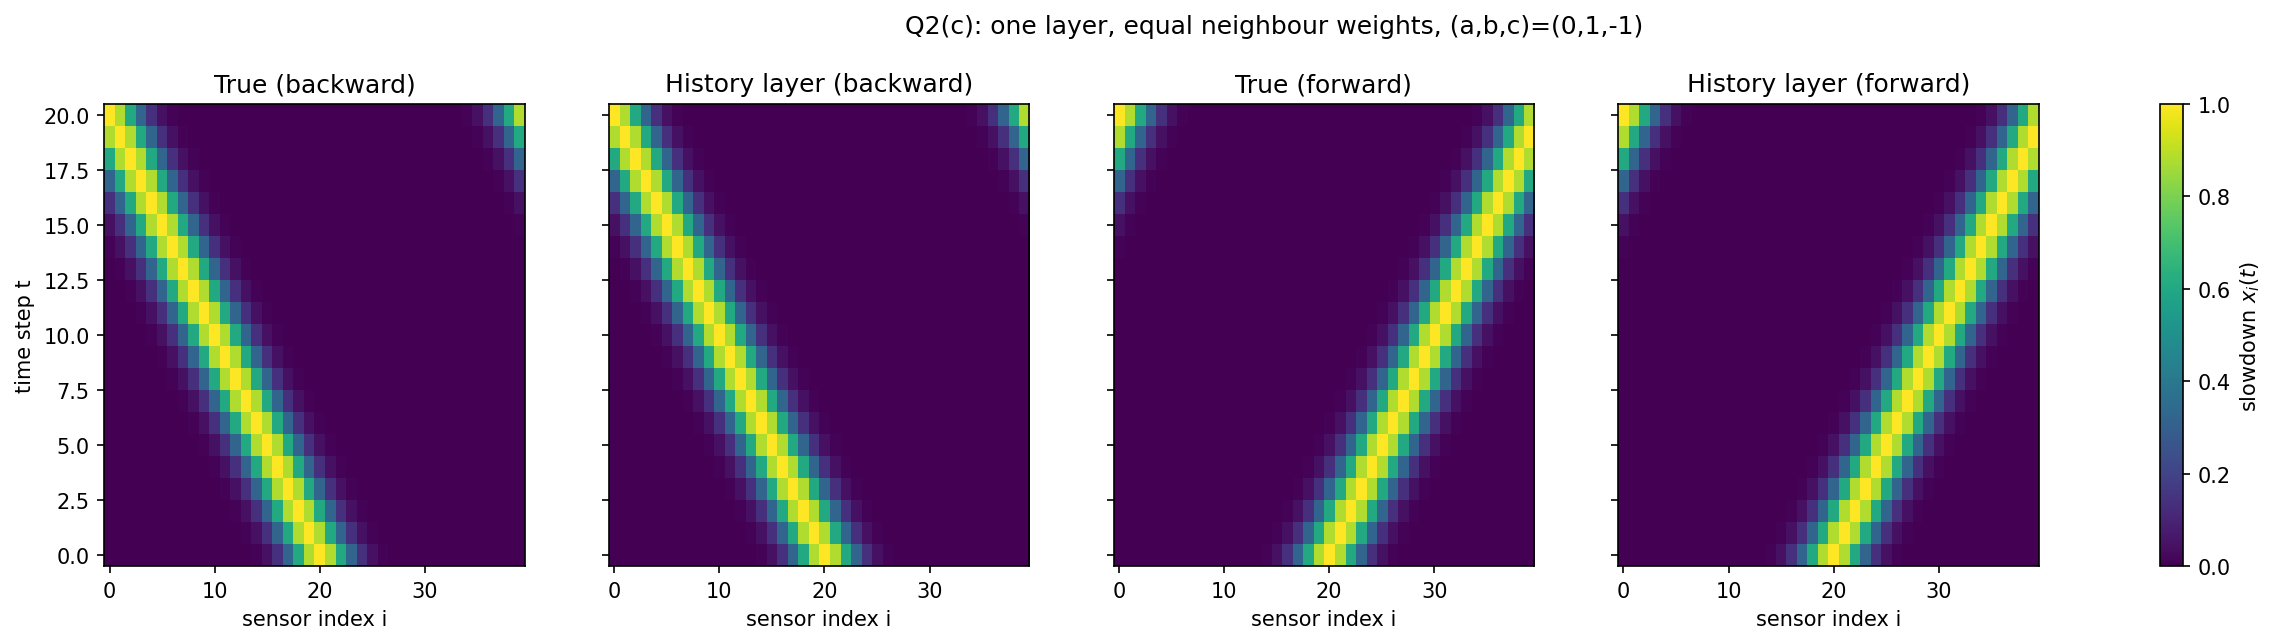

In [6]:
!cd {CODE} && python q2_direction.py
show('q2')

## Question 3 — Dataset preparation and graph construction

Downloads `ca_meta.csv`, `ca_rn_adj.npy`, `ca_his_raw_2020.h5`, `ca_his_raw_2021.h5` from Kaggle (`liuxu77/largest`) **only if the processed San Diego file is not already on Drive**.
You need a Kaggle API token: kaggle.com → Settings → API → *Create New Token* (downloads `kaggle.json`). It is uploaded once and kept on Drive.

In [10]:
# Kaggle credentials (skipped automatically if the processed dataset already exists on Drive)
processed = os.path.join(os.environ['PA3_DATA_DIR'], 'processed', 'sd_flow15.npz')
if os.path.exists(processed):
    print('Processed dataset found on Drive -> no download needed.')
else:
    os.makedirs('/root/.kaggle', exist_ok=True)
    kj = f'{BASE}/kaggle.json'
    if not os.path.exists(kj):
        print('Upload your kaggle.json'); up = files.upload()
        shutil.copy(next(iter(up)), kj)
    shutil.copy(kj, '/root/.kaggle/kaggle.json'); os.chmod('/root/.kaggle/kaggle.json', 0o600)
    !kaggle datasets files liuxu77/largest

Upload your kaggle.json


Saving kaggle.json to kaggle.json
name                      size  creationDate                
------------------  ----------  --------------------------  
ca_his_raw_2017.h5  7233256952  2023-06-13 11:28:22.455000  
ca_his_raw_2018.h5  7233256952  2023-06-13 11:28:20.814000  
ca_his_raw_2019.h5  7233256952  2023-06-13 11:28:18.310000  
ca_his_raw_2020.h5  7253073656  2023-06-13 11:28:14.781000  
ca_his_raw_2021.h5  7233256952  2023-06-13 11:28:06.156000  
ca_meta.csv             570431  2023-06-13 11:25:29.591000  
ca_rn_adj.npy        591680128  2023-06-13 11:25:38.802000  



  Q3(a)  Data extraction and resampling
[kaggle] downloading ca_meta.csv ...
Dataset URL: https://www.kaggle.com/datasets/liuxu77/largest
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)

 
  0%|          | 0.00/557k [00:00<?, ?B/s]
100%|██████████| 557k/557k [00:01<00:00, 500kB/s]
100%|██████████| 557k/557k [00:01<00:00, 499kB/s]

[kaggle] downloading ca_rn_adj.npy ...
Dataset URL: https://www.kaggle.com/datasets/liuxu77/largest
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)

 
  0%|          | 0.00/2.32M [00:00<?, ?B/s]
 43%|████▎     | 1.00M/2.32M [00:01<00:01, 950kB/s]
 86%|████████▌ | 2.00M/2.32M [00:01<00:00, 1.84MB/s]
100%|██████████| 2.32M/2.32M [00:01<00:00, 1.81MB/s]

[kaggle] downloading ca_his_raw_2020.h5 ...
Dataset URL: https://www.kaggle.com/datasets/liuxu77/largest
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)

 01:16<00:01, 20.7MB/s]
 98%|█████████▊| 1.37G/1.39G [01:17<00:01, 14.8MB/s]
 98%|███████

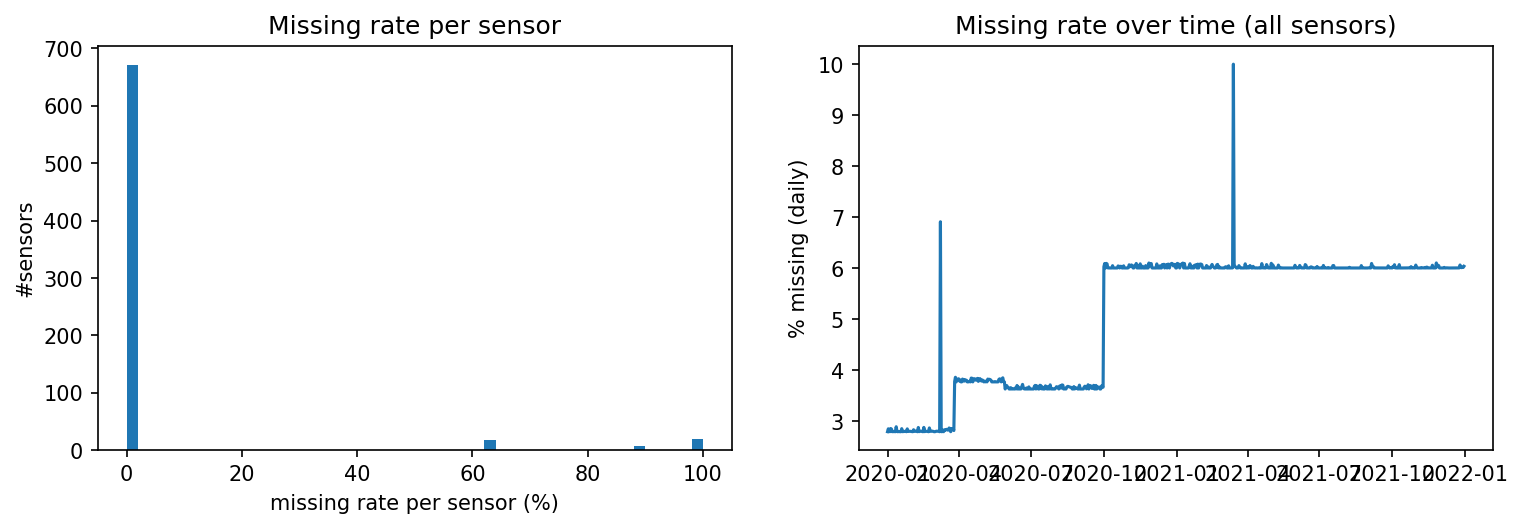

q3a_three_sensors_one_week.png


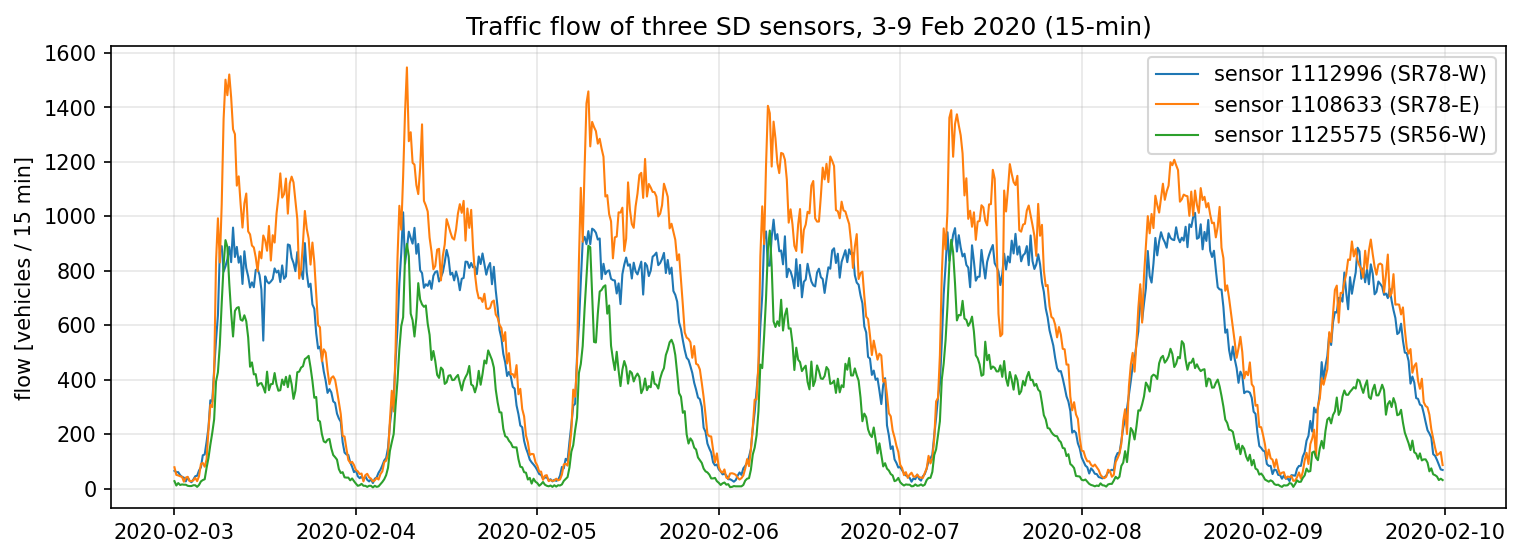

q3b_adjacency_heatmap.png


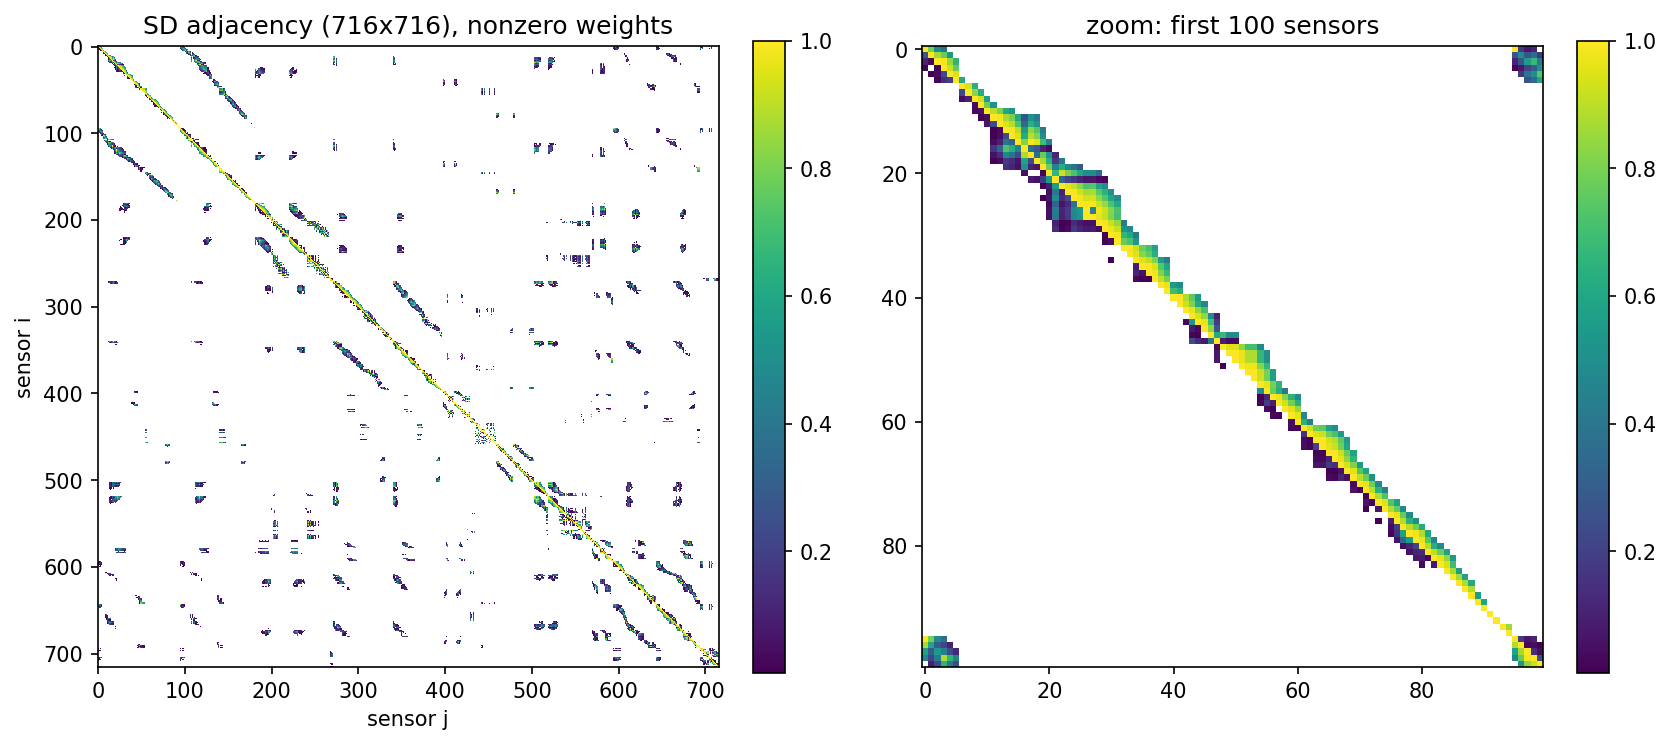

q3b_degree_distribution.png


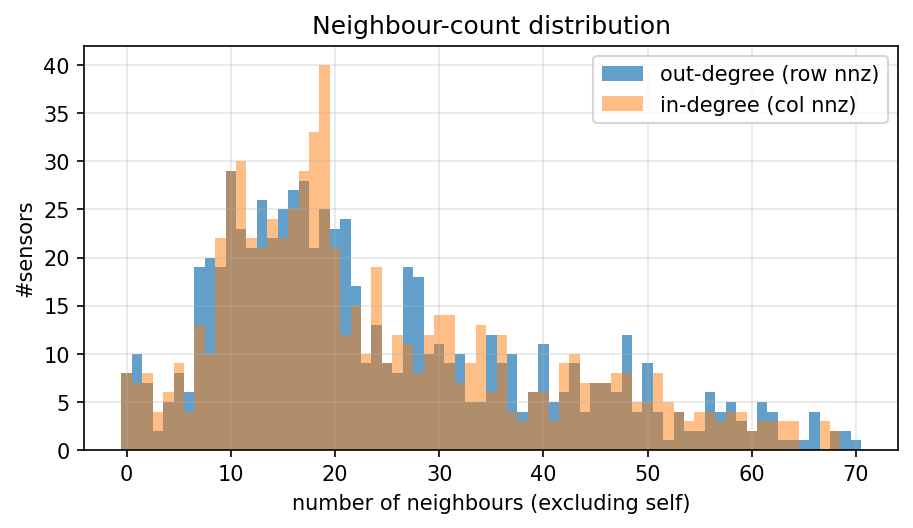

q3c_neighbourhood_map.png


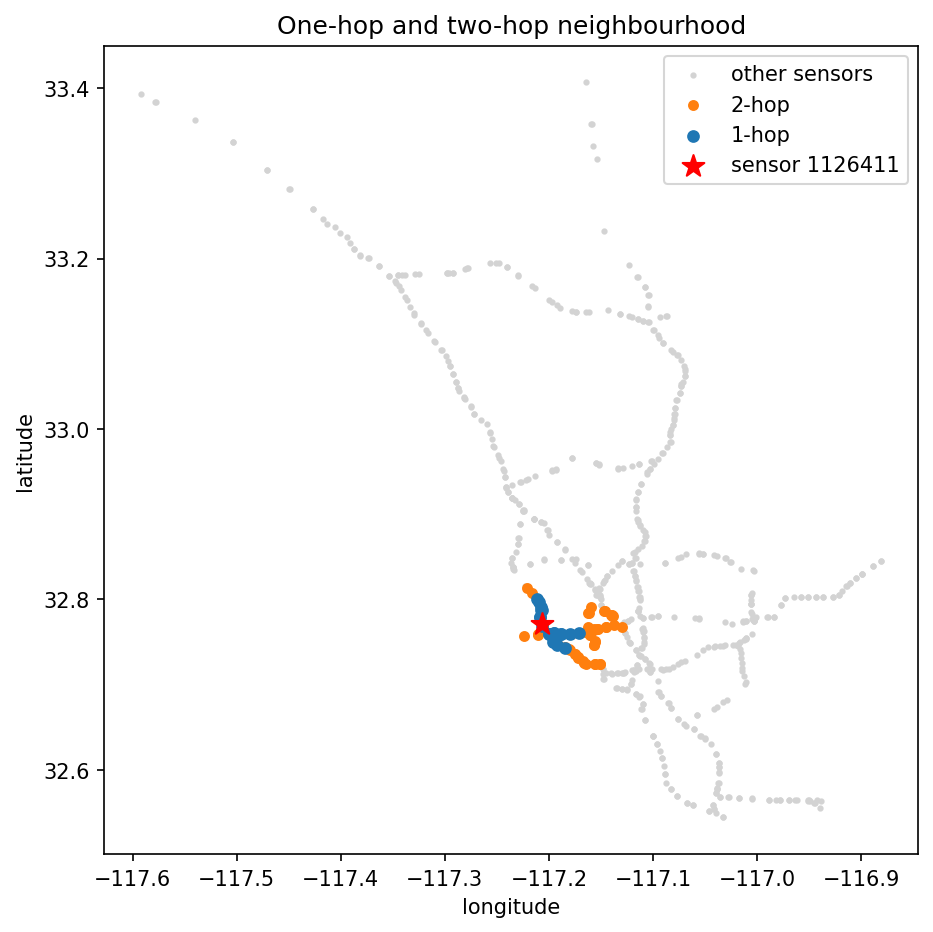

q3c_neighbourhood_zoom.png


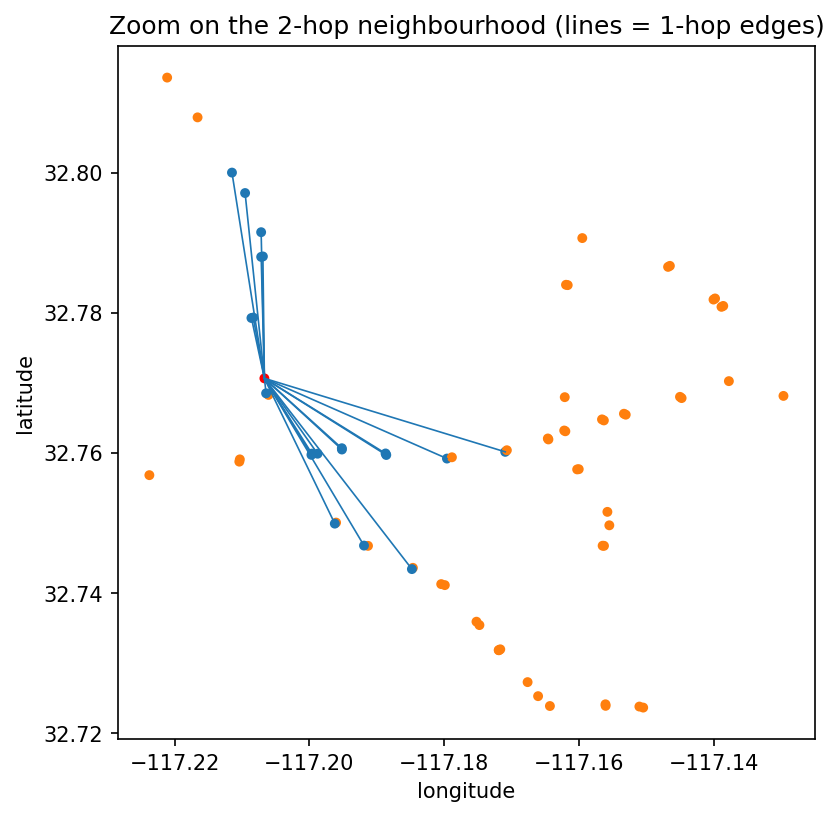

q3c_receptive_field_growth.png


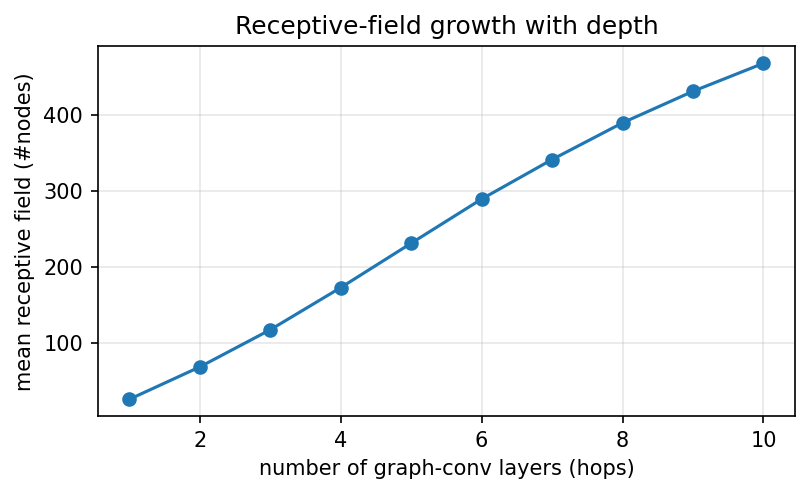

In [11]:
# --agg sum : 15-min flow = sum of three 5-min vehicle counts (vehicles / 15 min)
# --agg mean: average of the three 5-min counts (LargeST convention). Add --force to rebuild.
!cd {CODE} && python q3_dataset.py --agg sum
show('q3')

## Question 4 — Spatio-temporal forecasting (STGNN with fixed graph + temporal-only baseline)

/content/pa3/data_utils.py:61: RuntimeWarning: Mean of empty slice
  tr_mean_sensor = np.nanmean(np.where(mask[train], flow[train], np.nan), 0)

  Q4(a)  Forecasting windows
  X_t = [x_(t-7) .. x_t] -> 8 x 716 x 1,   Y_t = [x_(t+1) .. x_(t+4)] -> 4 x 716 x 1
  train:  35125 windows | first input 2020-01-01 00:00:00 | last target 2020-12-31 23:45:00
  val  :   8629 windows | first input 2021-01-01 00:00:00 | last target 2021-03-31 23:45:00
  test :  26389 windows | first input 2021-04-01 00:00:00 | last target 2021-12-31 23:45:00
  normalisation (2020 observed values only): mean = 607.386, std = 483.770
  A window is kept only if its 12 timestamps lie inside one split -> no window crosses a boundary.
[fig] saved /content/drive/MyDrive/AI651_PA3/outputs/figures/q4a_splits.png

  Q4(b)  STGNN with the fixed road-distance graph

### stgnn_fixed: adj_mode=fixed, params=13,668, device=cuda, train windows=35125, fixed-adj normalisation=row
  ep   1 | train MAE 158.861 | val MAE 143.163 RMSE 2

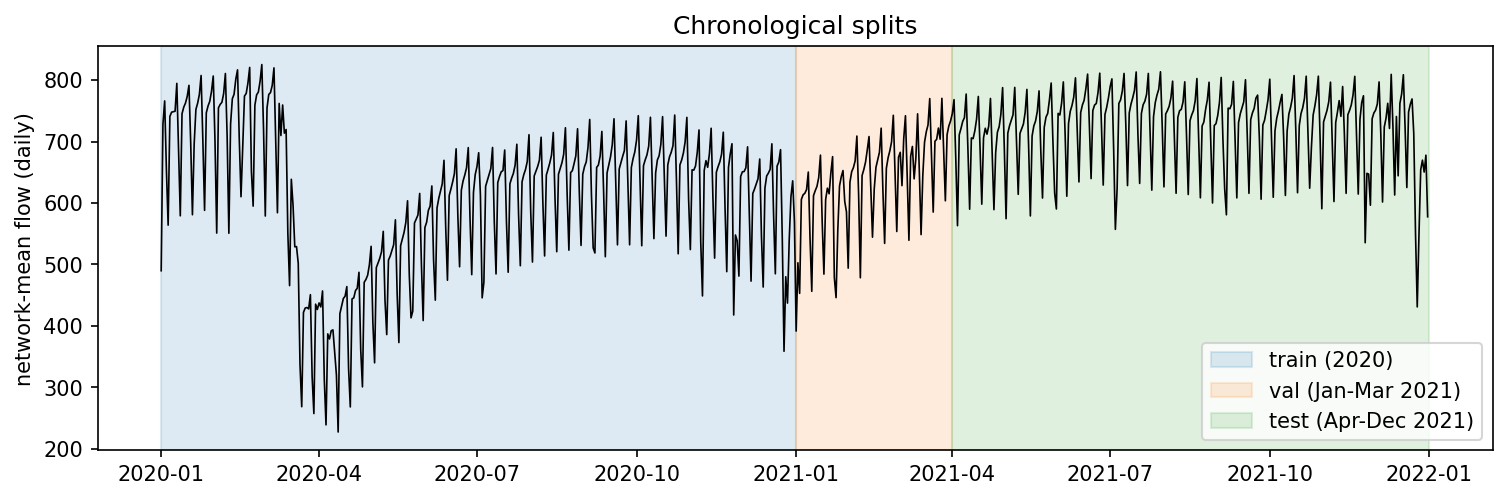

q4c_temporal_vs_graph.png


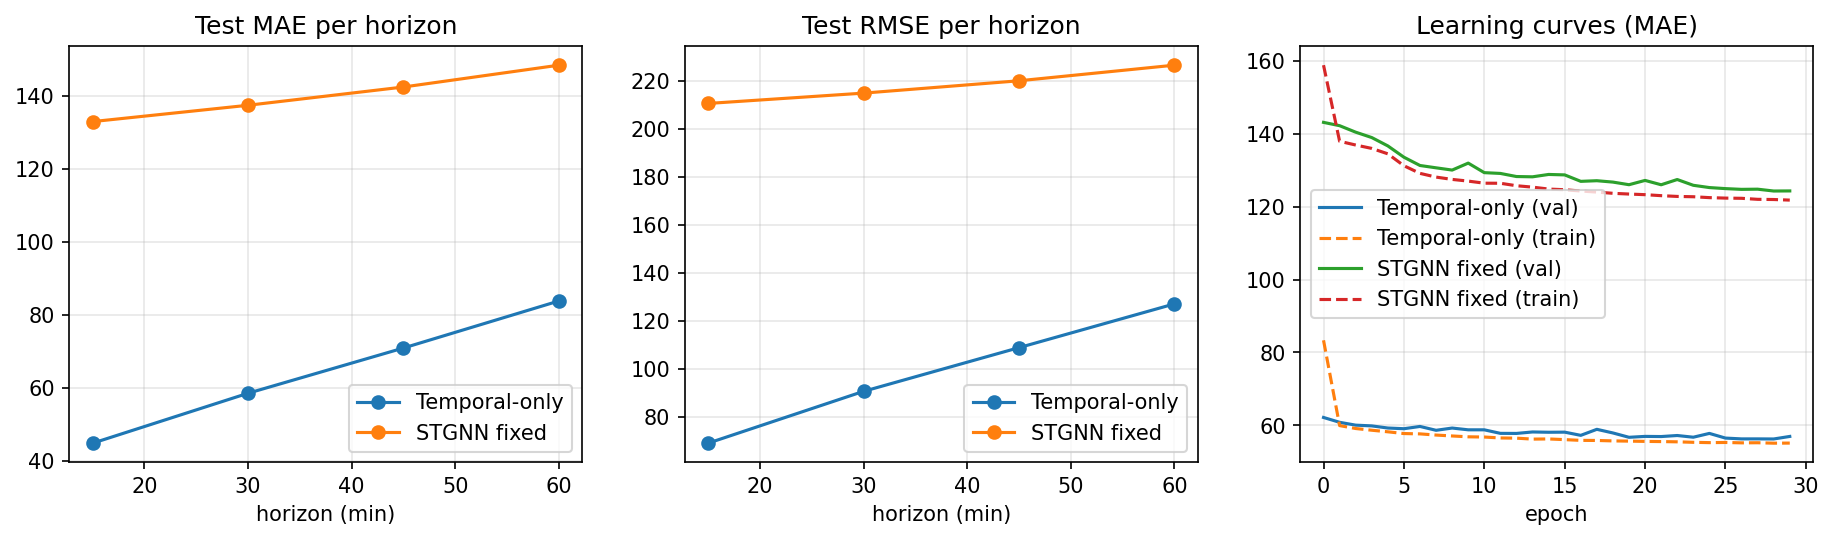

| Model               |   Val MAE |   Val RMSE |   Test MAE |   Test RMSE |   Params |   Train time (min) |
|:--------------------|----------:|-----------:|-----------:|------------:|---------:|-------------------:|
| Temporal-only       |    56.249 |     90.456 |     64.552 |     101.312 |    12644 |              8.153 |
| STGNN (fixed graph) |   124.317 |    200.128 |    140.232 |     218.19  |    13668 |              8.604 |

In [12]:
!cd {CODE} && python q4_stgnn.py {TRAIN_ARGS}
show('q4')
show_md('q4_comparison.md')

## Question 5 — Fixed vs learnable vs hybrid adjacency
(The fixed-graph model from Q4 is reused — same architecture and protocol.)

/content/pa3/data_utils.py:61: RuntimeWarning: Mean of empty slice
  tr_mean_sensor = np.nanmean(np.where(mask[train], flow[train], np.nan), 0)

  Q5(a)  Fixed adjacency
  normalisation used: row  (D^-1 (A+I), rows sum to 1 (directed graph))
[skip] stgnn_fixed: results already in /content/drive/MyDrive/AI651_PA3/outputs/results/metrics_stgnn_fixed.json (use --force to retrain)

  Q5(b)  Learnable (adaptive) adjacency
  E1, E2 in R^(716 x 10); A = softmax_row(relu(E1 E2^T)); top-k = none (dense)

### stgnn_adaptive: adj_mode=adaptive, params=27,988, device=cuda, train windows=35125, fixed-adj normalisation=row
  ep   1 | train MAE 168.472 | val MAE 117.559 RMSE 183.609 | 18.2s *
  ep   2 | train MAE 101.778 | val MAE 99.753 RMSE 156.952 | 17.8s *
  ep   3 | train MAE 89.944 | val MAE 94.115 RMSE 147.765 | 17.8s *
  ep   4 | train MAE 84.326 | val MAE 88.049 RMSE 140.911 | 17.6s *
  ep   5 | train MAE 80.396 | val MAE 84.998 RMSE 136.719 | 17.6s *
  ep   6 | train MAE 77.638 | val MAE 84

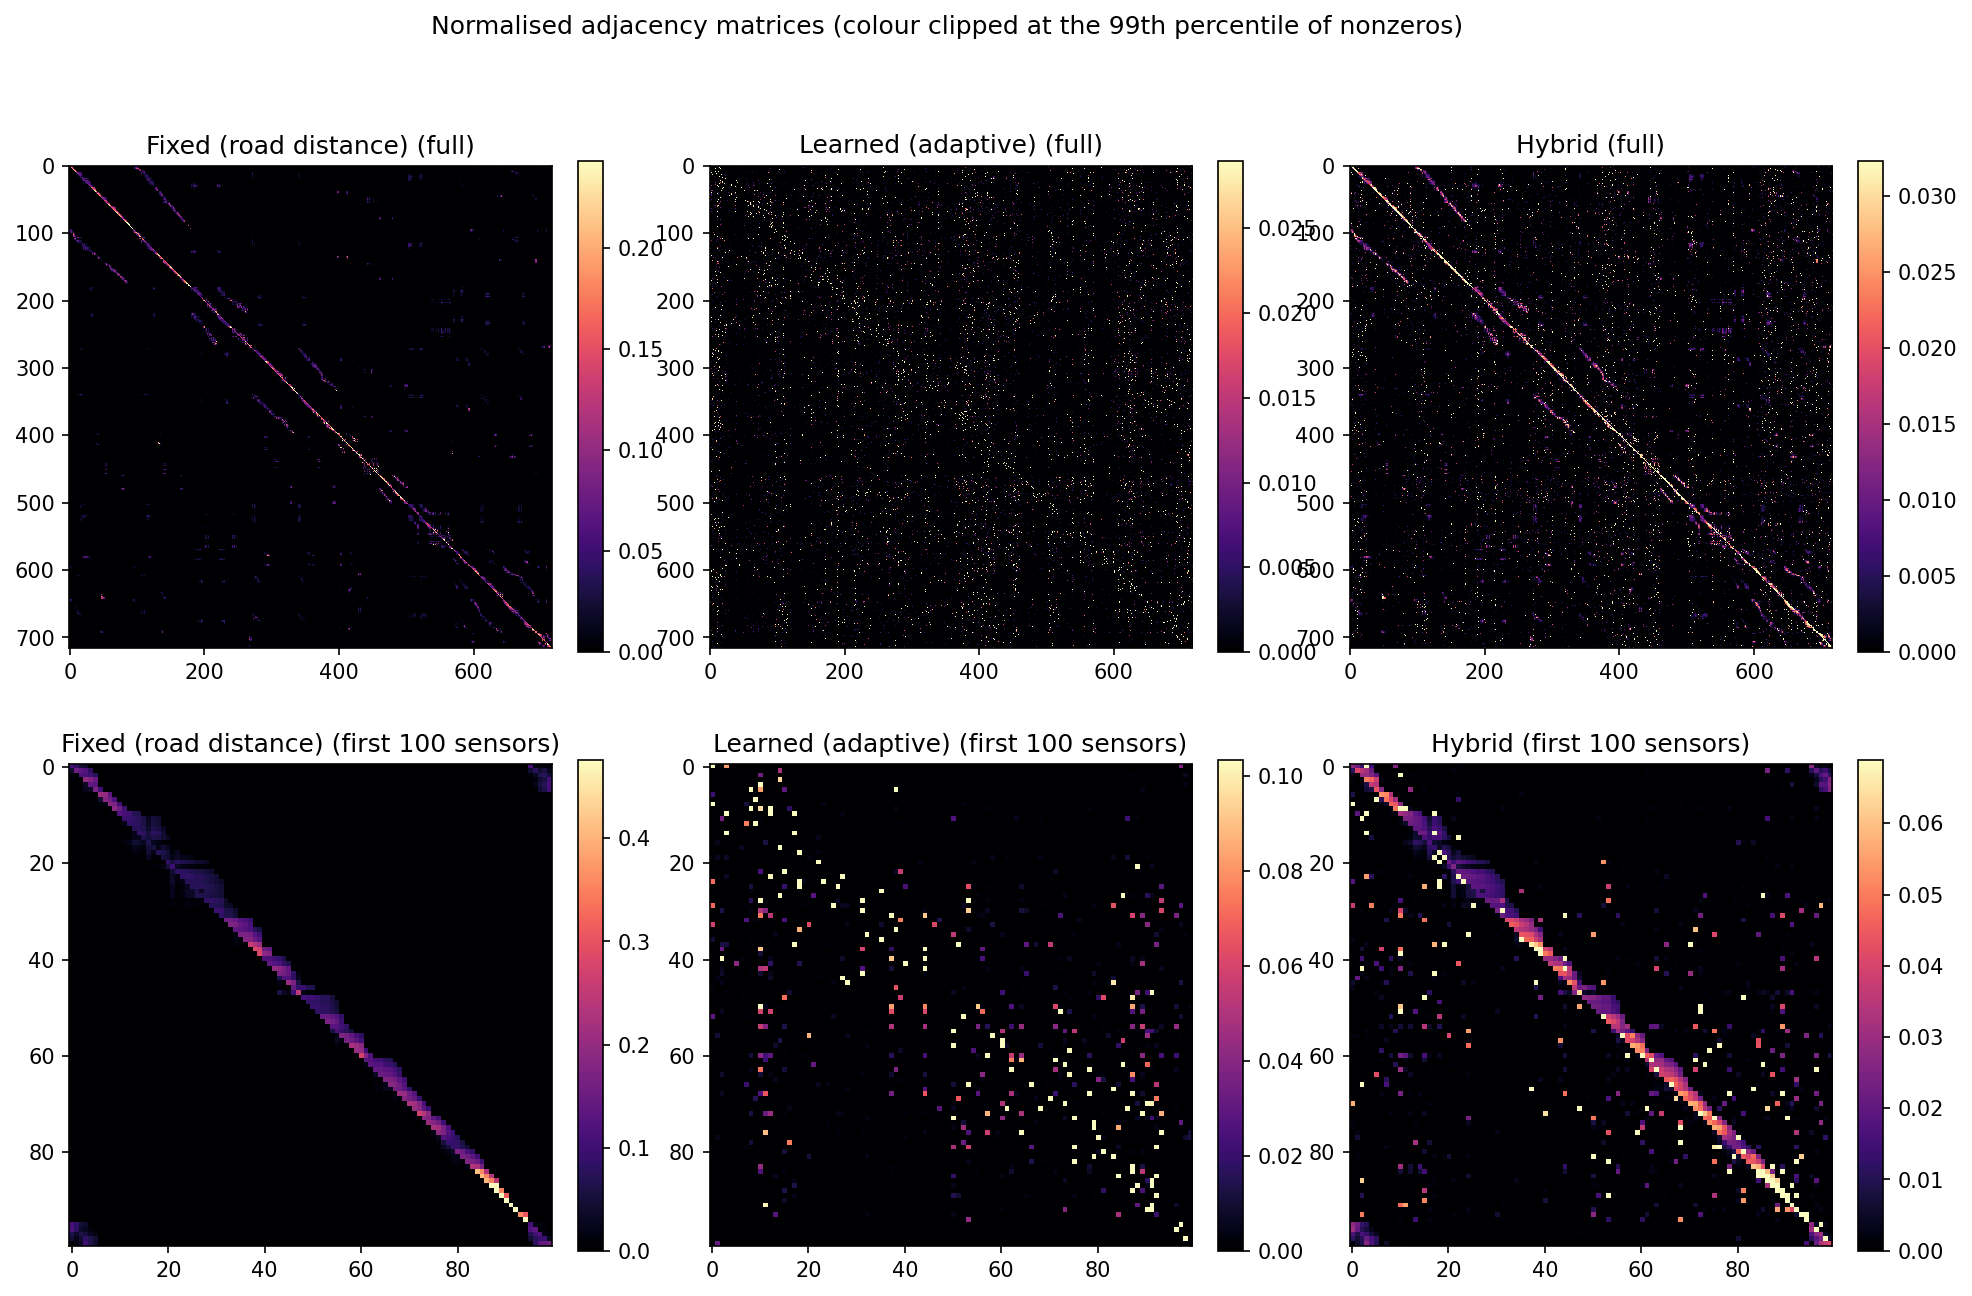

q5_learning_curves.png


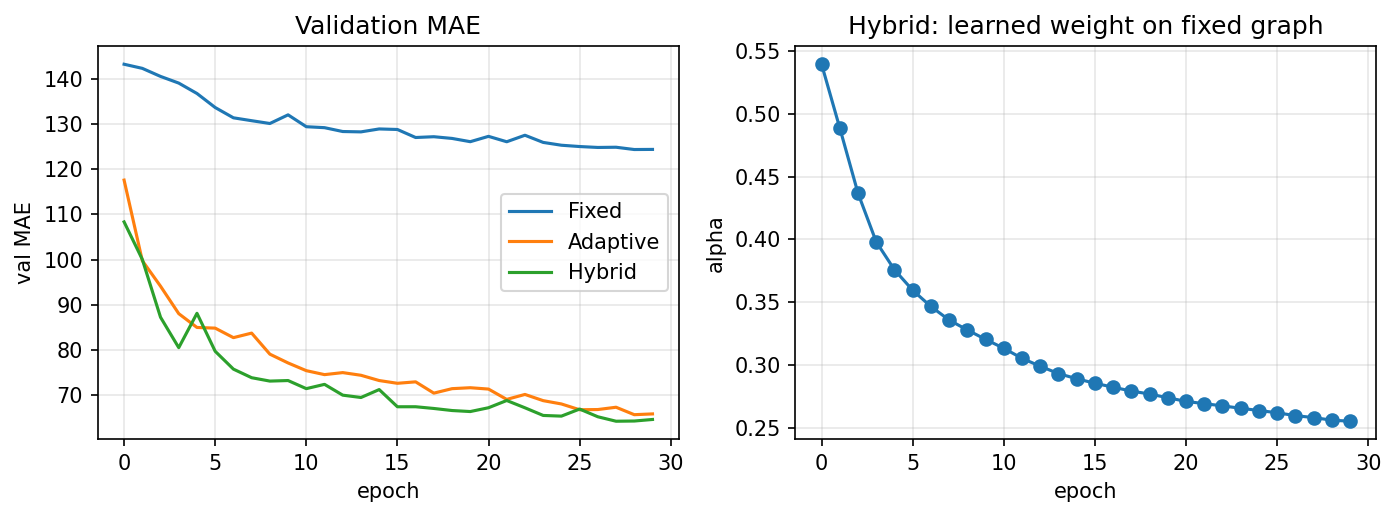

q5b_learned_graph_rows.png


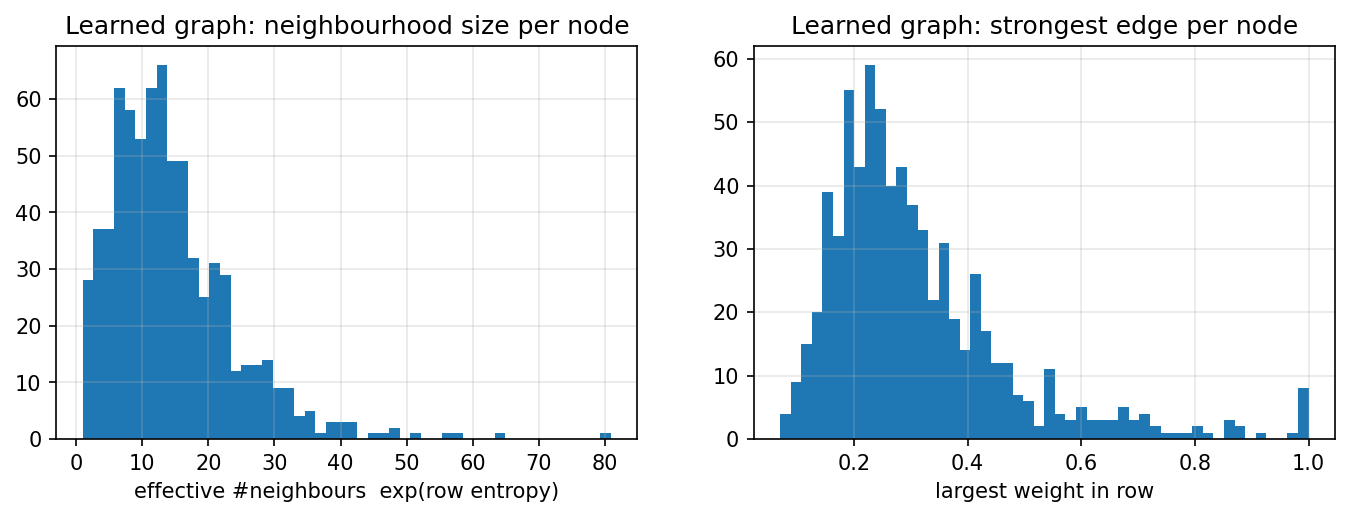

| Adjacency   |   Val MAE |   Val RMSE |   Test MAE |   Test RMSE |   Params |   Epochs |   Train time (min) |   s/epoch |
|:------------|----------:|-----------:|-----------:|------------:|---------:|---------:|-------------------:|----------:|
| Fixed       |   124.317 |    200.128 |    140.232 |     218.19  |    13668 |       30 |              8.604 |    17.209 |
| Adaptive    |    65.726 |    112.267 |     82.169 |     129.802 |    27988 |       30 |              8.845 |    17.69  |
| Hybrid      |    64.279 |    110.505 |     79.31  |     125.542 |    27989 |       30 |              8.871 |    17.742 |

In [13]:
!cd {CODE} && python q5_adjacency.py {TRAIN_ARGS}
show('q5')
show_md('q5_comparison.md')

## Question 6 — Experimental analysis and interpretation


  Q6(a)  Forecasting comparison
        Model Adjacency     MAE    RMSE              Training time
Temporal-only      None  64.552 101.312 8.2 min (30 ep, 16.3 s/ep)
        STGNN     Fixed 140.232 218.190 8.6 min (30 ep, 17.2 s/ep)
        STGNN  Adaptive  82.169 129.802 8.8 min (30 ep, 17.7 s/ep)
        STGNN    Hybrid  79.310 125.542 8.9 min (30 ep, 17.7 s/ep)
[txt] saved /content/drive/MyDrive/AI651_PA3/outputs/results/q6_final_table.md
[fig] saved /content/drive/MyDrive/AI651_PA3/outputs/figures/q6a_metric_bars.png
[fig] saved /content/drive/MyDrive/AI651_PA3/outputs/figures/q6a_pred_vs_actual_15min.png
[fig] saved /content/drive/MyDrive/AI651_PA3/outputs/figures/q6a_pred_vs_actual_60min.png
[fig] saved /content/drive/MyDrive/AI651_PA3/outputs/figures/q6a_best_model_one_day_all_horizons.png

  Q6(b)  Graph structure analysis
  (1) top-10 learned neighbours per node present in road graph: 6.56% (random baseline = graph density 3.38%; x1.9)
      strongest 7160 learned edges overa

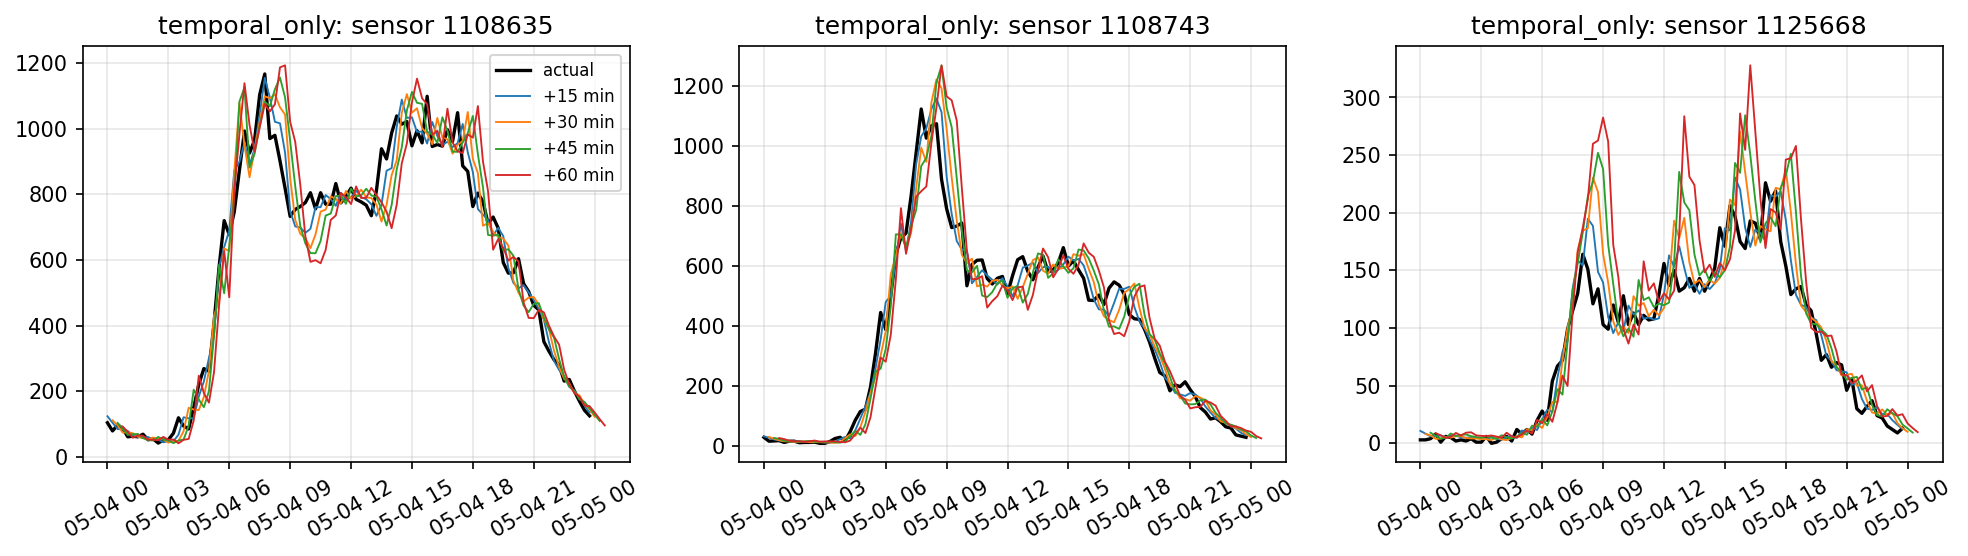

q6a_metric_bars.png


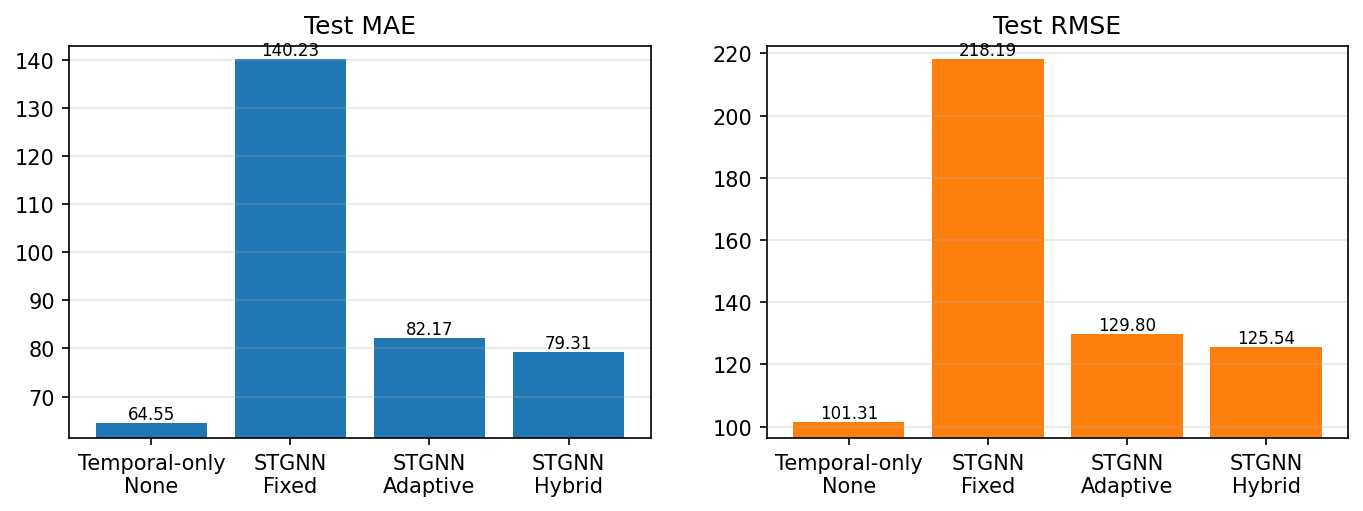

q6a_pred_vs_actual_15min.png


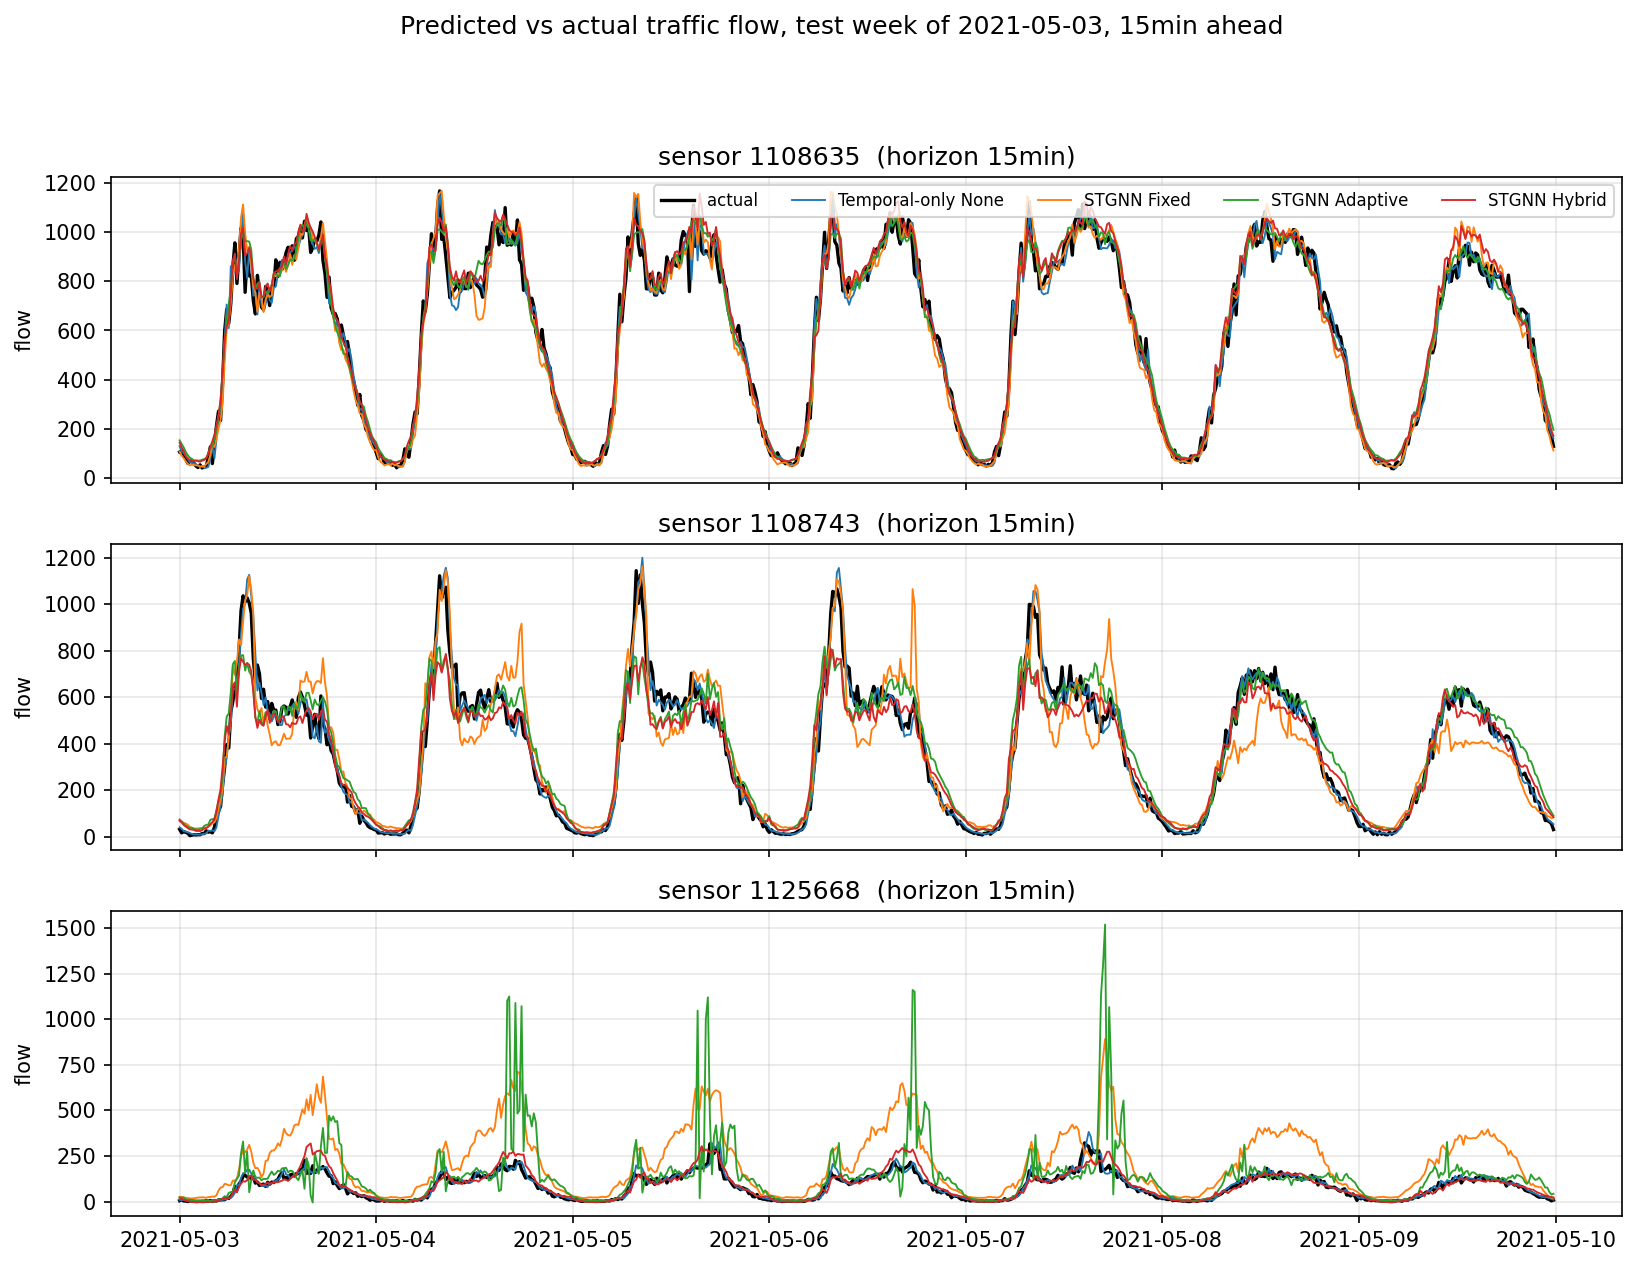

q6a_pred_vs_actual_60min.png


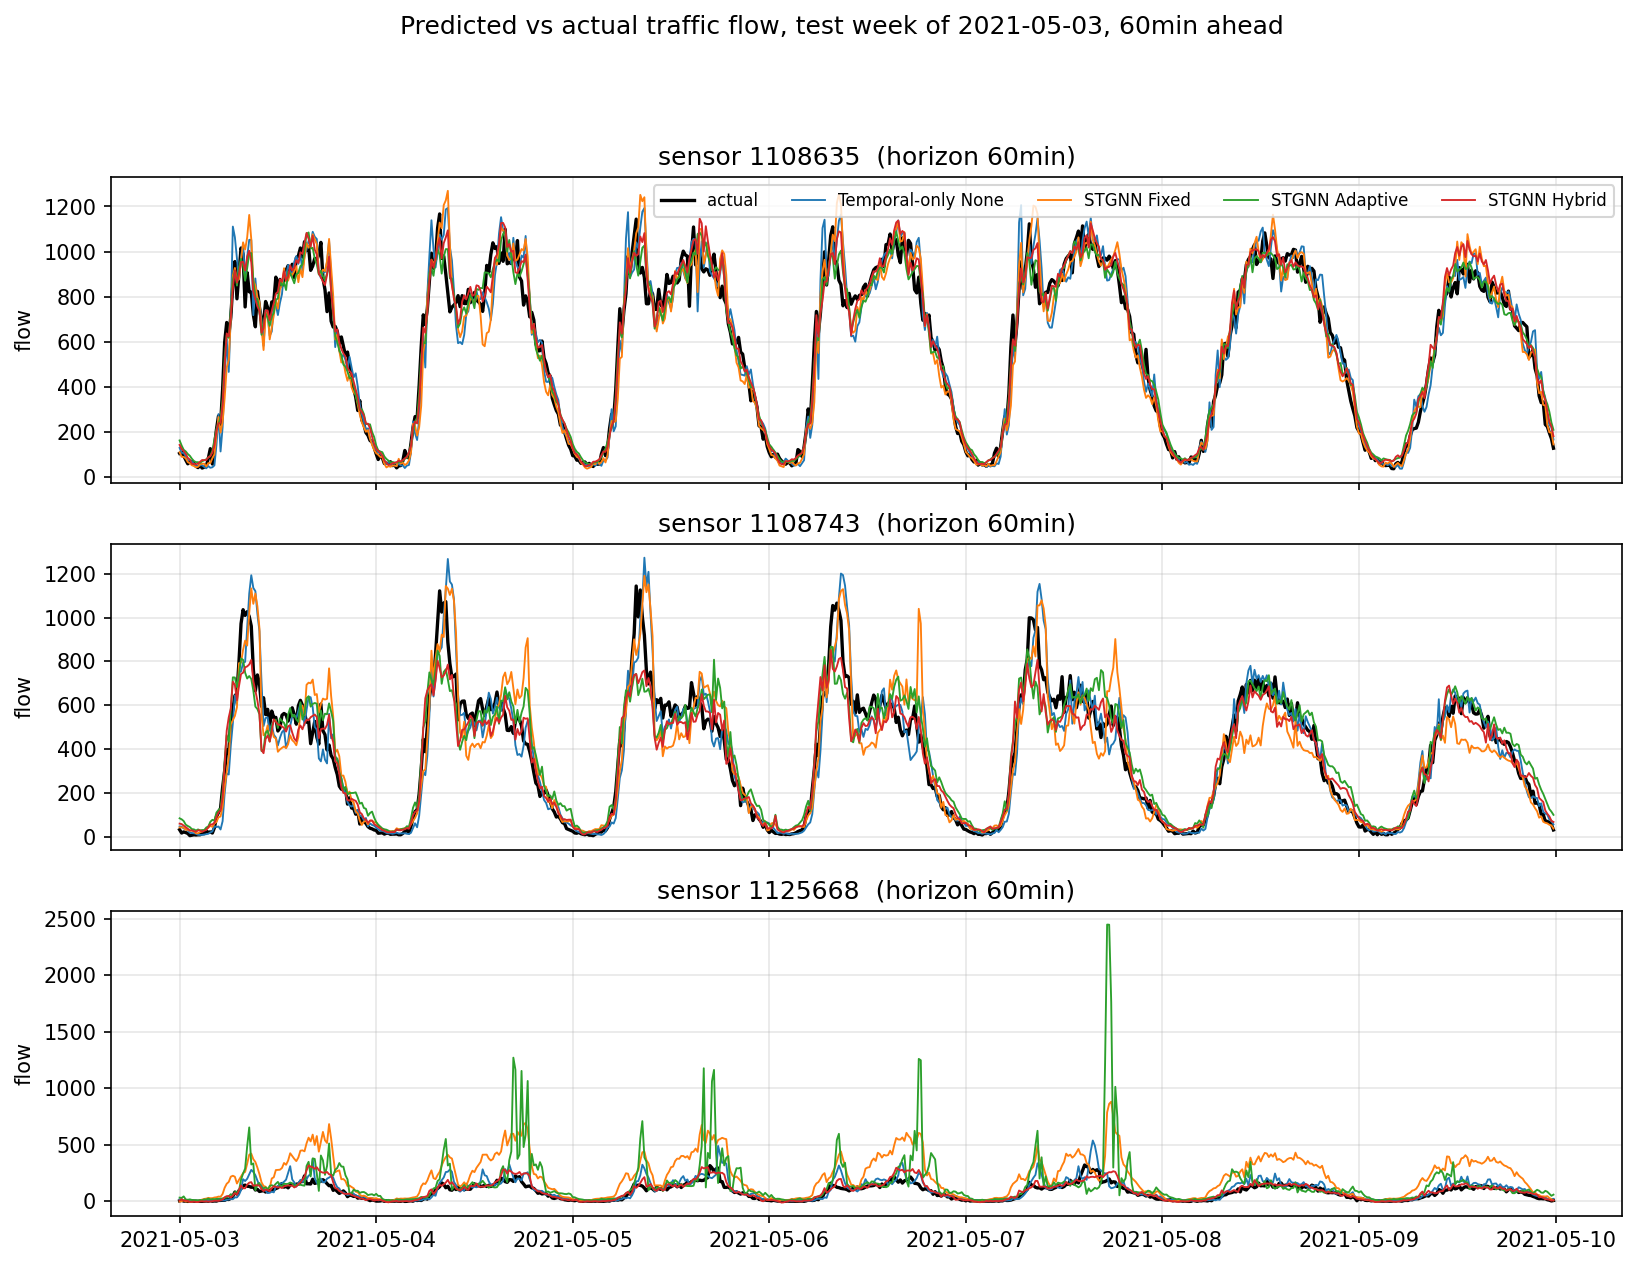

q6b_correlation_of_learned_edges.png


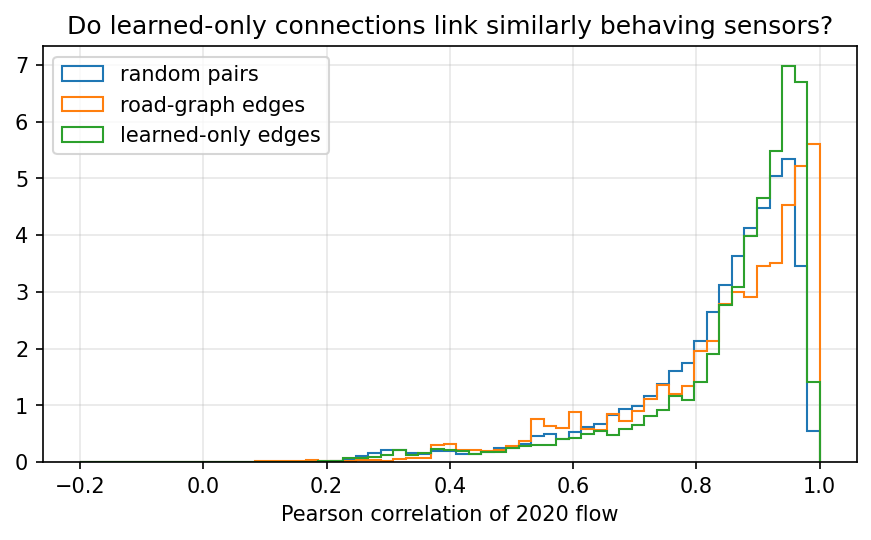

q6b_distance_distribution.png


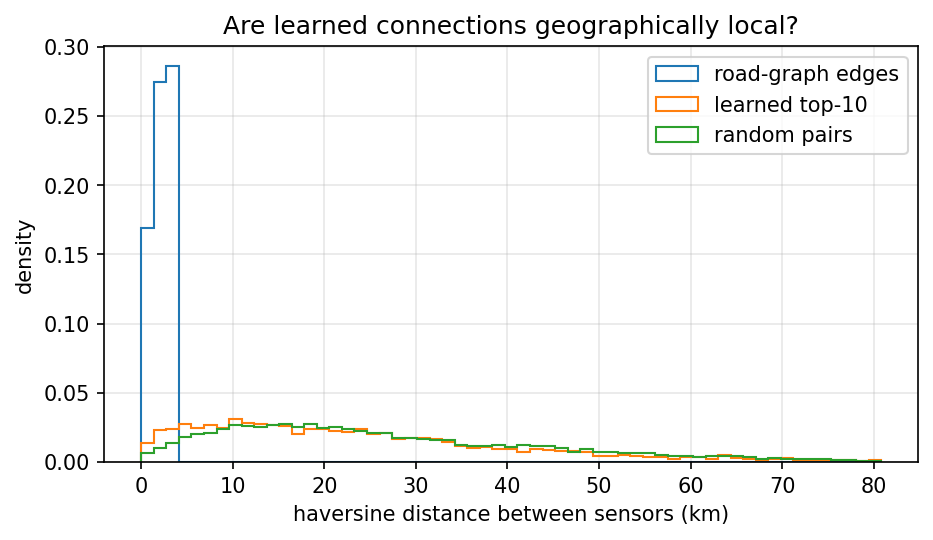

q6b_learned_edges_map.png


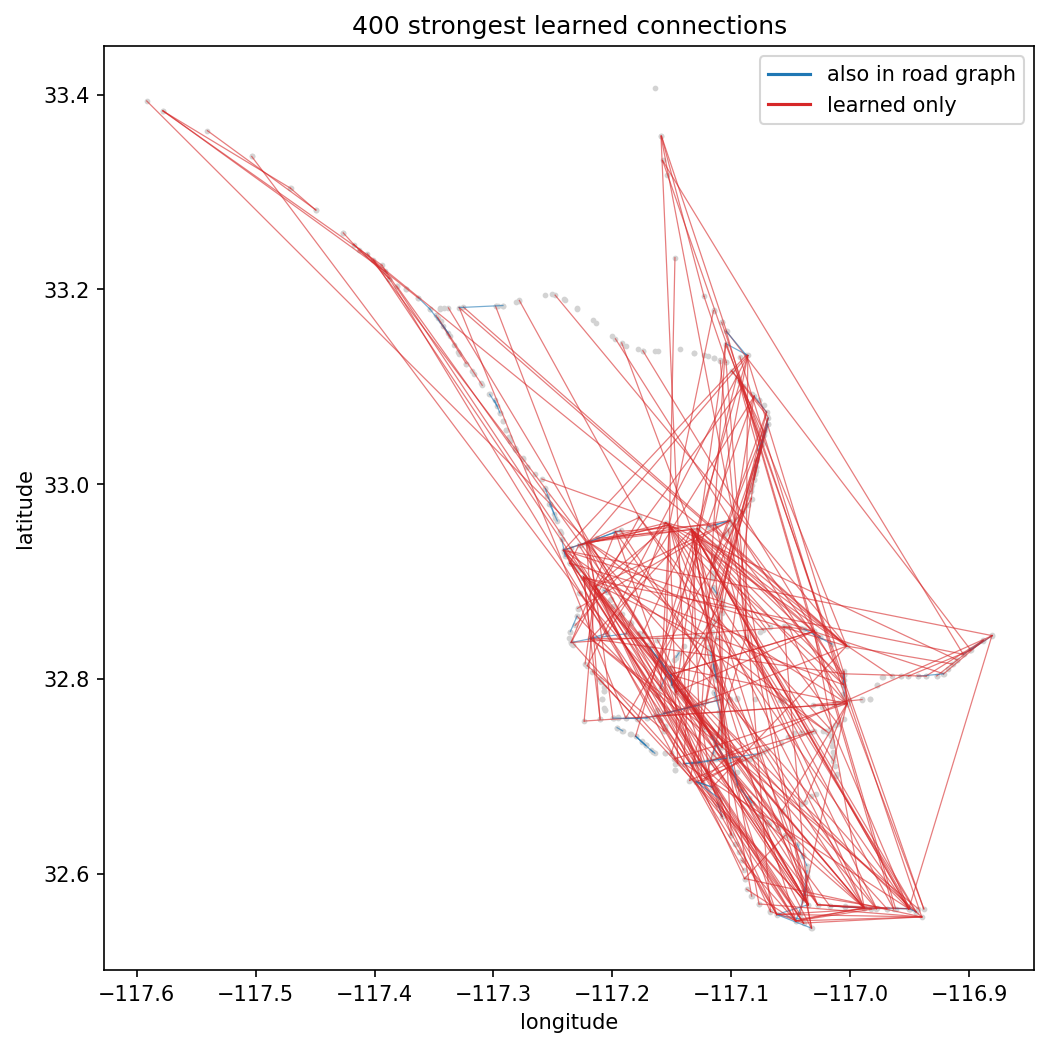

q6b_road_vs_learned_sorted.png


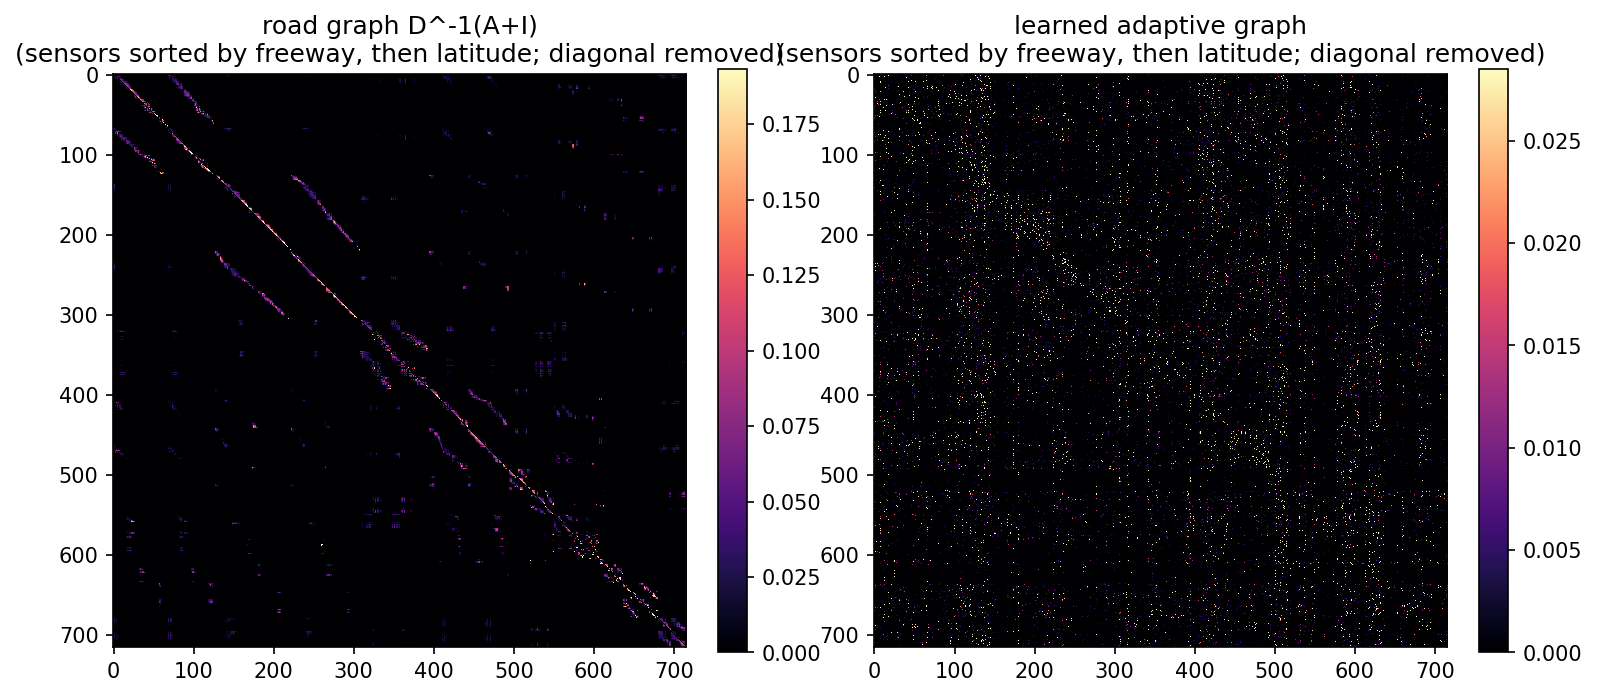

Test-set results (Apr-Dec 2021), original flow units

| Model         | Adjacency   |     MAE |    RMSE | Training time              |
|:--------------|:------------|--------:|--------:|:---------------------------|
| Temporal-only | None        |  64.552 | 101.312 | 8.2 min (30 ep, 16.3 s/ep) |
| STGNN         | Fixed       | 140.232 | 218.19  | 8.6 min (30 ep, 17.2 s/ep) |
| STGNN         | Adaptive    |  82.169 | 129.802 | 8.8 min (30 ep, 17.7 s/ep) |
| STGNN         | Hybrid      |  79.31  | 125.542 | 8.9 min (30 ep, 17.7 s/ep) |

Full:

| Model         | Adjacency   |     MAE |    RMSE | Training time              |   Val MAE |   Val RMSE |   MAE@15min |   MAE@30min |   MAE@45min |   MAE@60min |
|:--------------|:------------|--------:|--------:|:---------------------------|----------:|-----------:|------------:|------------:|------------:|------------:|
| Temporal-only | None        |  64.552 | 101.312 | 8.2 min (30 ep, 16.3 s/ep) |    56.249 |     90.456 |      44.897 |      58.562 |      70.939 |      83.812 |
| STGNN         | Fixed       | 140.232 | 218.19  | 8.6 min (30 ep, 17.2 s/ep) |   124.317 |    200.128 |     132.891 |     137.358 |     142.355 |     148.325 |
| STGNN         | Adaptive    |  82.169 | 129.802 | 8.8 min (30 ep, 17.7 s/ep) |    65.726 |    112.267 |      75.858 |      79.903 |      83.783 |      89.132 |
| STGNN         | Hybrid      |  79.31  | 125.542 | 8.9 min (30 ep, 17.7 s/ep) |    64.279 |    110.505 |      72.717 |      76.525 |      81.053 |      86.947 |

In [14]:
!cd {CODE} && python q6_analysis.py --k 10
show('q6')
show_md('q6_final_table.md')

## Question 7 — Reproducibility and reporting

In [15]:
!cd {CODE} && python q7_report.py > /dev/null
show_md('reproducibility.md')

# Reproducibility summary (AI651 PA3)

## Hardware / software
- **python**: 3.13.16
- **platform**: Linux-6.6.159+-x86_64-with-glibc2.39
- **processor**: x86_64
- **cpu_cores_logical**: 2
- **cpu_cores_physical**: 1
- **ram_gb**: 13.6
- **cpu_model**: Intel(R) Xeon(R) CPU @ 2.00GHz
- **torch**: 2.14.1+cu130
- **cuda_available**: True
- **gpu**: Tesla T4
- **gpu_mem_gb**: 15.6
- **cuda**: 13.0
- **numpy**: 2.4.6
- **pandas**: 2.2.3
- **matplotlib**: 3.10.0
- **h5py**: 3.14.0

## Data
- LargeST San Diego (District 11), 716 sensors, 2020-2021, 5-min -> 15-min (sum of three 5-min counts; unit: vehicles / 15 min)
- Missing 15-min values: 5.06%
- Missing targets masked in loss and metrics; inputs forward-filled (causal), leading gaps = 2020 sensor mean
- Splits: train 2020, val Jan-Mar 2021, test Apr-Dec 2021; z-score with 2020 statistics only
- Input 8 steps (2 h) -> output 4 steps (1 h); windows never cross split boundaries
- Windows: train 35125, val 8629, test 26389

## Models, hyperparameters and training
| Model | Adjacency | Params | Epochs run | Best epoch | s/epoch | Train time (min) | Test MAE | Test RMSE |
|---|---|---|---|---|---|---|---|---|
| Temporal-only | None | 12,644 | 30 | 29 | 16.3 | 8.15 | 64.552 | 101.312 |
| STGNN | Fixed | 13,668 | 30 | 29 | 17.2 | 8.60 | 140.232 | 218.190 |
| STGNN | Adaptive | 27,988 | 30 | 29 | 17.7 | 8.85 | 82.169 | 129.802 |
| STGNN | Hybrid | 27,989 | 30 | 28 | 17.7 | 8.87 | 79.310 | 125.542 |

Shared hyperparameters (identical for all models):

- epochs: 30
- patience: 6
- batch_size: 64
- lr: 0.001
- weight_decay: 0.0
- hidden: 32
- emb_dim: 10
- topk: 0
- alpha: None
- train_stride: 1
- seed: 42
- in_len: 8
- out_len: 4
- loss: masked MAE
- optimizer: Adam
- grad_clip: 5.0
- Temporal encoder: Conv1d(1->d,k=3) -> ReLU -> Conv1d(d->d,k=3,dilation=2) -> ReLU -> Linear(8d->d) -> ReLU
- Graph conv: H = ReLU(A_hat Z W_g), W_g in R^{d x d}
- Head: Linear(d->d) -> ReLU -> Linear(d->4)
- Fixed graph: D^-1(A+I) if A is directed, else D^-1/2(A+I)D^-1/2
- Adaptive graph: softmax_row(ReLU(E1 E2^T)), E1,E2 ~ N(0,1) init
- Hybrid: alpha*D^-1(A+I) + (1-alpha)*A_adaptive, alpha = sigmoid(learned scalar), init 0.5
- Early stopping on validation MAE; best checkpoint evaluated on test
- Final learned alpha: 0.2580

## Figures

- q1b_encoding_injective.png
- q2a_heatmaps.png
- q2a_profiles_t20.png
- q2b_heatmaps.png
- q2c_heatmaps.png
- q3a_missing_values.png
- q3a_three_sensors_one_week.png
- q3b_adjacency_heatmap.png
- q3b_degree_distribution.png
- q3c_neighbourhood_map.png
- q3c_neighbourhood_zoom.png
- q3c_receptive_field_growth.png
- q4a_splits.png
- q4c_temporal_vs_graph.png
- q5_adjacency_matrices.png
- q5_learning_curves.png
- q5b_learned_graph_rows.png
- q6a_best_model_one_day_all_horizons.png
- q6a_metric_bars.png
- q6a_pred_vs_actual_15min.png
- q6a_pred_vs_actual_60min.png
- q6b_correlation_of_learned_edges.png
- q6b_distance_distribution.png
- q6b_learned_edges_map.png
- q6b_road_vs_learned_sorted.png

## How to reproduce

```
pip install -r requirements.txt
export PA3_DATA_DIR=<folder for LargeST files>  PA3_OUT_DIR=<output folder>
python q1_aggregation.py
python q2_direction.py
python q3_dataset.py
python q4_stgnn.py --epochs 30 --hidden 32 --seed 42
python q5_adjacency.py --epochs 30 --hidden 32 --seed 42
python q6_analysis.py
python q7_report.py
```

## Download all figures and results (for the report)

In [16]:
# figures + results only (checkpoints stay on Drive)
!cd {os.environ['PA3_OUT_DIR']} && zip -qr /content/pa3_figures_results.zip figures results
files.download('/content/pa3_figures_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes
- Everything is also on Drive under `AI651_PA3/outputs/` (`figures/*.png|pdf`, `results/*.json|csv|md`).
- To retrain a model from scratch add `--force` to its command (or delete its `metrics_*.json` and checkpoints).
- Remember the course AI-use disclosure (prompts, outputs, edits) at the end of your report.